In [3]:
# BLOC 1 — Charger, nettoyer, agréger par catégorie
import pandas as pd

# Lire le fichier (en-tête des colonnes sur la 3e ligne = index 2)
df = pd.read_excel("../data/Value per month per Chain - Product.xlsx", header=2)
# Enlever les lignes vides (bas de tableau, totaux)
df = df.dropna(subset=["Chain - Product"])

# Convertir la date texte en vraie date
df["date"] = pd.to_datetime(df["reference_date"])

# Agréger par catégorie et par mois (la somme règle aussi les doublons de SKU)
cat = (df.groupby(["product_line", "date"])["value"].sum()
         .reset_index()
         .rename(columns={"product_line": "categorie", "value": "ventes"}))

# Vérifications
print("Nombre de lignes après agrégation :", len(cat))
print("\nNombre de mois par catégorie :")
print(cat.groupby("categorie")["date"].nunique())
print("\nAperçu Dog :")
print(cat[cat["categorie"] == "Dog"].head(6).to_string(index=False))

Nombre de lignes après agrégation : 190

Nombre de mois par catégorie :
categorie
Cat           43
Cat Treats    18
Dental        43
Dog           43
Dog Treats    43
Name: date, dtype: int64

Aperçu Dog :
categorie       date    ventes
      Dog 2023-01-31  56504.03
      Dog 2023-02-28  53432.85
      Dog 2023-03-31 101062.96
      Dog 2023-04-30  74147.96
      Dog 2023-05-31  86241.36
      Dog 2023-06-30  85828.71


Train : 31 mois (de 2023-01-31 à 2025-07-31)
Test  : 12 mois  (de 2025-08-31 à 2026-07-31)

>>> MAPE de la baseline saisonnière sur Dog : 25.8%


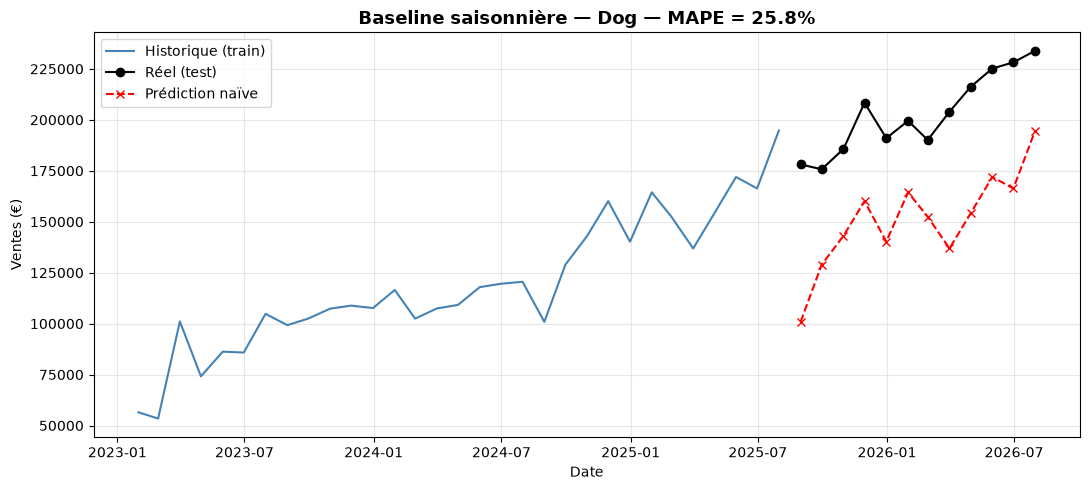

In [5]:
# BLOC 2 — Baseline saisonnière naïve sur Dog
import numpy as np
import matplotlib.pyplot as plt

# 1) Isoler la série Dog, triée par date
dog = cat[cat["categorie"] == "Dog"].sort_values("date").reset_index(drop=True)

# 2) Découper train / test : les 12 derniers mois en test
n_test = 12
train = dog.iloc[:-n_test].copy()
test  = dog.iloc[-n_test:].copy()

print(f"Train : {len(train)} mois (de {train['date'].min().date()} à {train['date'].max().date()})")
print(f"Test  : {len(test)} mois  (de {test['date'].min().date()} à {test['date'].max().date()})")

# 3) Prédiction naïve : chaque valeur de test = valeur du même mois, 12 mois plus tôt
predictions = []
for date_test in test["date"]:
    date_precedente = date_test - pd.DateOffset(years=1)
    valeur = dog.loc[dog["date"] == date_precedente, "ventes"].values[0]
    predictions.append(valeur)

test["prediction"] = predictions

# 4) Calcul du MAPE (Mean Absolute Percentage Error)
test["erreur_pct"] = np.abs(test["ventes"] - test["prediction"]) / test["ventes"] * 100
mape = test["erreur_pct"].mean()

print(f"\n>>> MAPE de la baseline saisonnière sur Dog : {mape:.1f}%")

# 5) Graphique
plt.figure(figsize=(11, 5))
plt.plot(train["date"], train["ventes"], label="Historique (train)", color="steelblue")
plt.plot(test["date"],  test["ventes"], label="Réel (test)", color="black", marker="o")
plt.plot(test["date"],  test["prediction"], label="Prédiction naïve", color="red", marker="x", linestyle="--")
plt.title(f"Baseline saisonnière — Dog — MAPE = {mape:.1f}%", fontsize=13, fontweight="bold")
plt.xlabel("Date"); plt.ylabel("Ventes (€)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/baseline_dog.png", dpi=110, bbox_inches="tight")
plt.show()

c:\Users\G096103\OneDrive - General Mills\Desktop\Eugenia\memoire_forecast_edgardcooper\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Importing plotly failed. Interactive plots will not work.
20:11:19 - cmdstanpy - INFO - Chain [1] start processing
20:11:20 - cmdstanpy - INFO - Chain [1] done processing


>>> MAPE Prophet sur Dog : 5.0%
>>> MAPE Baseline (rappel) : 25.8%
>>> Gain vs baseline : +20.8 points de MAPE


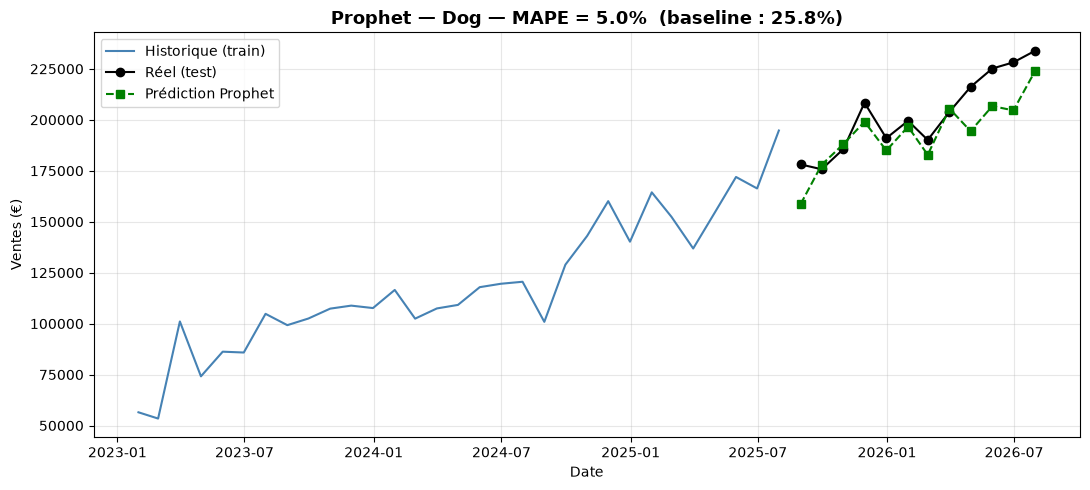

In [6]:
# BLOC 3 — Prophet sur Dog
from prophet import Prophet

# 1) Prophet exige exactement 2 colonnes nommées "ds" (date) et "y" (valeur).
#    On prépare la série complète Dog dans ce format.
dog_prophet = dog[["date", "ventes"]].rename(columns={"date": "ds", "ventes": "y"})

# 2) Même découpage train/test que pour la baseline (12 derniers mois en test)
n_test = 12
train_p = dog_prophet.iloc[:-n_test].copy()
test_p  = dog_prophet.iloc[-n_test:].copy()

# 3) Créer le modèle et l'entraîner uniquement sur le train
#    - yearly_seasonality=True : on demande explicitement la saisonnalité annuelle
#    - weekly/daily désactivées : on est en mensuel, ça n'a pas de sens
modele = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
modele.fit(train_p)

# 4) Créer les 12 dates futures à prédire (correspondent au test)
futur = modele.make_future_dataframe(periods=n_test, freq="ME")   # ME = month end
prevision = modele.predict(futur)

# 5) Récupérer uniquement les 12 dernières prédictions (celles qui correspondent au test)
pred_test = prevision[["ds", "yhat"]].iloc[-n_test:].reset_index(drop=True)

# 6) Calcul du MAPE — même méthode que pour la baseline, pour pouvoir comparer
comparaison = test_p.reset_index(drop=True).copy()
comparaison["prediction"] = pred_test["yhat"].values
comparaison["erreur_pct"] = np.abs(comparaison["y"] - comparaison["prediction"]) / comparaison["y"] * 100
mape_prophet = comparaison["erreur_pct"].mean()

print(f">>> MAPE Prophet sur Dog : {mape_prophet:.1f}%")
print(f">>> MAPE Baseline (rappel) : {mape:.1f}%")
gain = mape - mape_prophet
print(f">>> Gain vs baseline : {gain:+.1f} points de MAPE")

# 7) Graphique comparatif
plt.figure(figsize=(11, 5))
plt.plot(train_p["ds"], train_p["y"], label="Historique (train)", color="steelblue")
plt.plot(test_p["ds"],  test_p["y"], label="Réel (test)", color="black", marker="o")
plt.plot(comparaison["ds"], comparaison["prediction"], label="Prédiction Prophet", color="green", marker="s", linestyle="--")
plt.title(f"Prophet — Dog — MAPE = {mape_prophet:.1f}%  (baseline : {mape:.1f}%)", fontsize=13, fontweight="bold")
plt.xlabel("Date"); plt.ylabel("Ventes (€)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/prophet_dog.png", dpi=110, bbox_inches="tight")
plt.show()

Recherche des meilleurs paramètres SARIMA (peut prendre 20-40 secondes)...
Modèle retenu : (1, 0, 2) x (0, 1, 1, 12)

BENCHMARK SUR DOG
Baseline naïve : 25.8%
SARIMA         : 3.2%
Prophet        : 5.0%


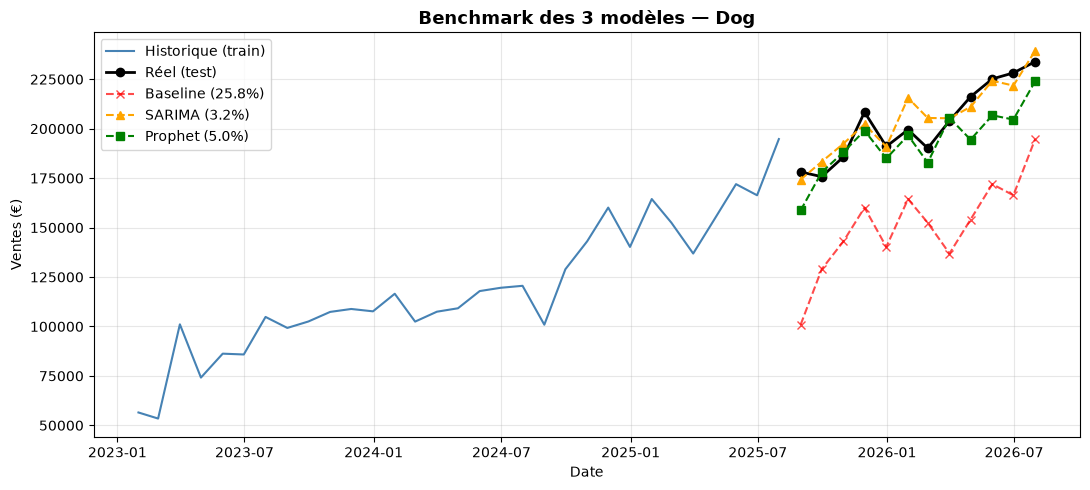

In [7]:
# BLOC 4 — SARIMA sur Dog (via auto_arima)
from pmdarima import auto_arima

# 1) Même découpage train/test qu'avant, pour être comparable
n_test = 12
serie = dog.sort_values("date").reset_index(drop=True)
train_s = serie.iloc[:-n_test]
test_s  = serie.iloc[-n_test:]

# 2) auto_arima cherche automatiquement les meilleurs paramètres SARIMA
#    m=12 : période saisonnière annuelle (12 mois)
#    seasonal=True : on active la composante saisonnière
#    stepwise=True : recherche rapide (au lieu de tester TOUTES les combinaisons)
print("Recherche des meilleurs paramètres SARIMA (peut prendre 20-40 secondes)...")
modele_sarima = auto_arima(
    train_s["ventes"],
    seasonal=True,
    m=12,
    stepwise=True,
    suppress_warnings=True,
    trace=False,
)

print(f"Modèle retenu : {modele_sarima.order} x {modele_sarima.seasonal_order}")

# 3) Prévision sur les 12 mois de test
pred_sarima = modele_sarima.predict(n_periods=n_test)

# 4) Calcul du MAPE
comparaison_s = test_s.reset_index(drop=True).copy()
comparaison_s["prediction"] = pred_sarima.values
comparaison_s["erreur_pct"] = np.abs(comparaison_s["ventes"] - comparaison_s["prediction"]) / comparaison_s["ventes"] * 100
mape_sarima = comparaison_s["erreur_pct"].mean()

# 5) Récap comparatif des 3 modèles
print("\n" + "="*50)
print("BENCHMARK SUR DOG")
print("="*50)
print(f"Baseline naïve : {mape:.1f}%")
print(f"SARIMA         : {mape_sarima:.1f}%")
print(f"Prophet        : {mape_prophet:.1f}%")
print("="*50)

# 6) Graphique comparatif des 3 modèles
plt.figure(figsize=(11, 5))
plt.plot(train_s["date"], train_s["ventes"], label="Historique (train)", color="steelblue")
plt.plot(test_s["date"],  test_s["ventes"], label="Réel (test)", color="black", marker="o", linewidth=2)
plt.plot(test["date"],    test["prediction"], label=f"Baseline ({mape:.1f}%)", color="red", marker="x", linestyle="--", alpha=0.7)
plt.plot(comparaison_s["date"], comparaison_s["prediction"], label=f"SARIMA ({mape_sarima:.1f}%)", color="orange", marker="^", linestyle="--")
plt.plot(comparaison["ds"], comparaison["prediction"], label=f"Prophet ({mape_prophet:.1f}%)", color="green", marker="s", linestyle="--")
plt.title("Benchmark des 3 modèles — Dog", fontsize=13, fontweight="bold")
plt.xlabel("Date"); plt.ylabel("Ventes (€)")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/benchmark_dog.png", dpi=110, bbox_inches="tight")
plt.show()